deskripsi library yang digunakan

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

In [1]:
%pip install pandas numpy matplotlib seaborn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: C:\Users\HP5CD\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


# Membaca Dataset

In [8]:
df = pd.read_csv('toyota.csv')

In [14]:
df = pd.read_csv('toyota.csv')

df.head()

,model,year,price,transmission,mileage,fuelType,tax,mpg,engineSize
0,GT86,2016,16000,Manual,24089,Petrol,265,36.2,2.0
1,GT86,2017,15995,Manual,18615,Petrol,145,36.2,2.0
2,GT86,2015,13998,Manual,27469,Petrol,265,36.2,2.0
3,GT86,2017,18998,Manual,14736,Petrol,150,36.2,2.0
4,GT86,2017,17498,Manual,36284,Petrol,145,36.2,2.0


In [15]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6738 entries, 0 to 6737
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   model         6738 non-null   str    
 1   year          6738 non-null   int64  
 2   price         6738 non-null   int64  
 3   transmission  6738 non-null   str    
 4   mileage       6738 non-null   int64  
 5   fuelType      6738 non-null   str    
 6   tax           6738 non-null   int64  
 7   mpg           6738 non-null   float64
 8   engineSize    6738 non-null   float64
dtypes: float64(2), int64(4), str(3)
memory usage: 599.1 KB


# Melihat Dataset

In [9]:
df.head()

,model,year,price,transmission,mileage,fuelType,tax,mpg,engineSize
0,GT86,2016,16000,Manual,24089,Petrol,265,36.2,2.0
1,GT86,2017,15995,Manual,18615,Petrol,145,36.2,2.0
2,GT86,2015,13998,Manual,27469,Petrol,265,36.2,2.0
3,GT86,2017,18998,Manual,14736,Petrol,150,36.2,2.0
4,GT86,2017,17498,Manual,36284,Petrol,145,36.2,2.0


# Visualisasi Data

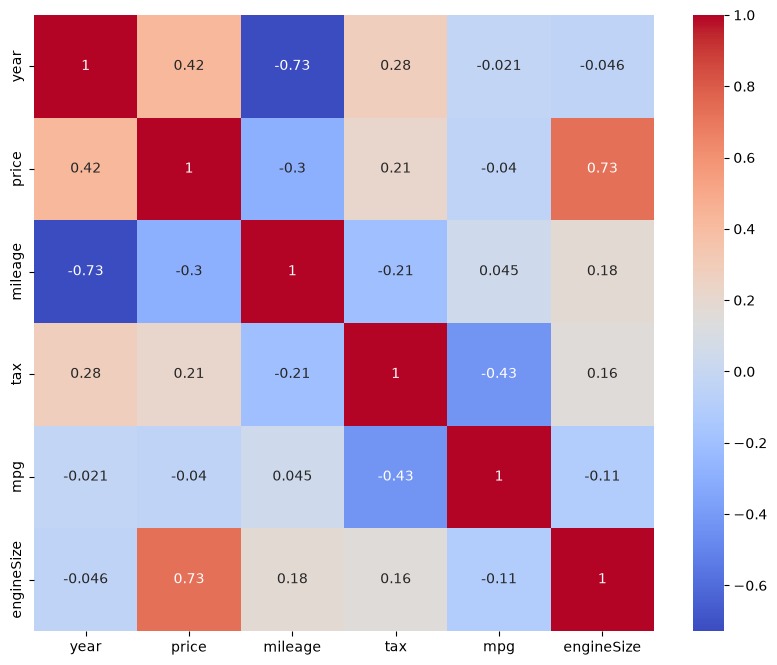

In [15]:
plt.figure(figsize=(10,8))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm')
plt.show()


# Jumlah mobil berdasarkan model


In [9]:
models = df.groupby('model').count()[['tax']].sort_values(by='tax',ascending=True).reset_index()
models = models.rename(columns={'tax':'nomberOfCars'})

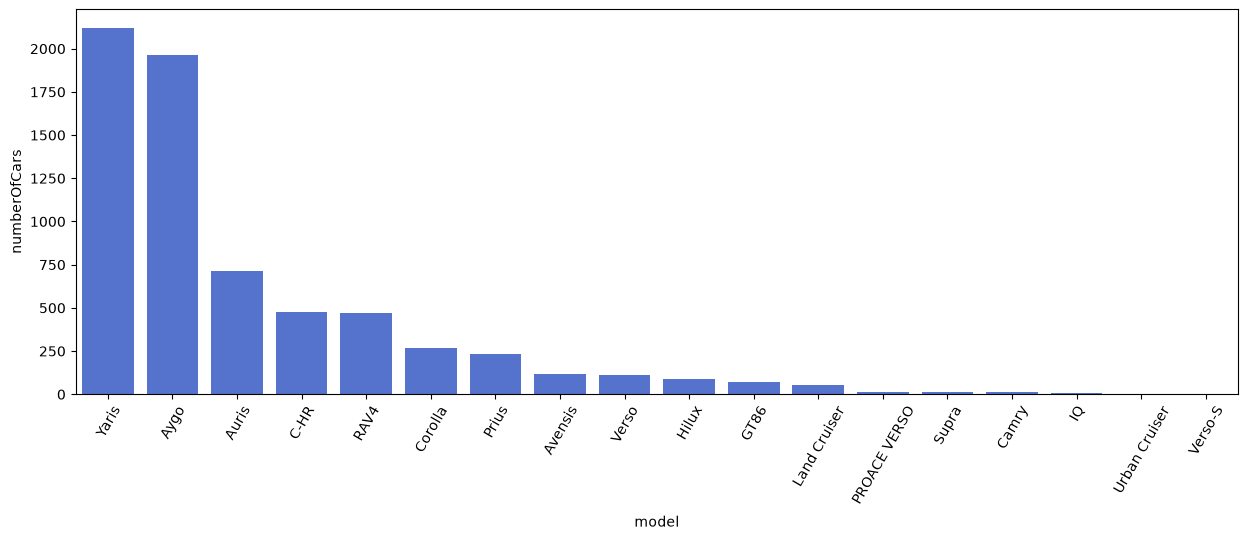

In [14]:
models = df['model'].value_counts().reset_index()
models.columns = ['model', 'numberOfCars']

fig = plt.figure(figsize=(15,5))
sns.barplot(x=models['model'], y=models['numberOfCars'], color='royalblue')

plt.xticks(rotation=60)
plt.show()

# Ukuran Mesin

In [17]:
engine = df.groupby('engineSize').count()[['tax']].sort_values(by='tax').reset_index()

engine = engine.rename(columns={'tax':'count'})

<Axes: xlabel='engineSize', ylabel='count'>

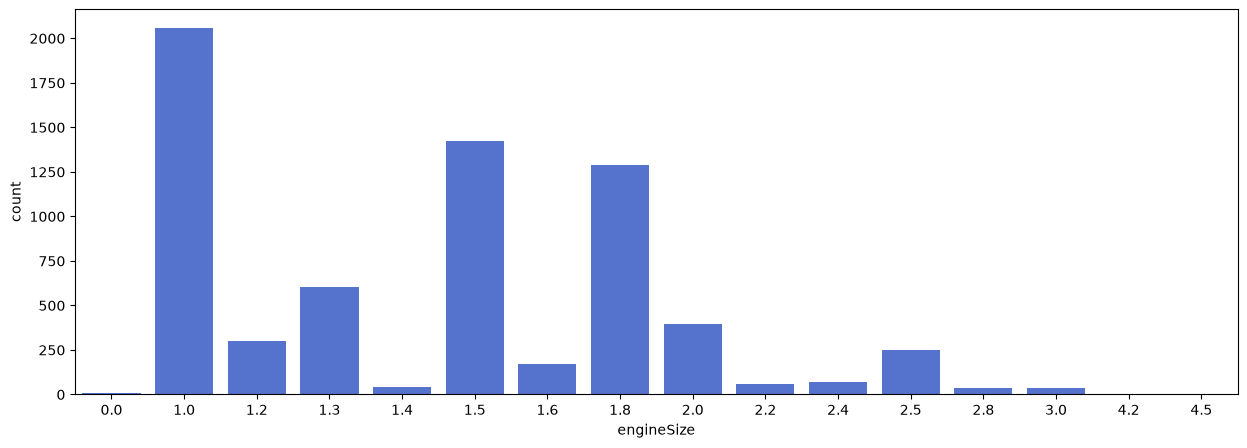

In [18]:
plt.figure(figsize=(15,5))
sns.barplot(x=engine['engineSize'], y=engine['count'], color='royalblue')

# Distribusi Mileage


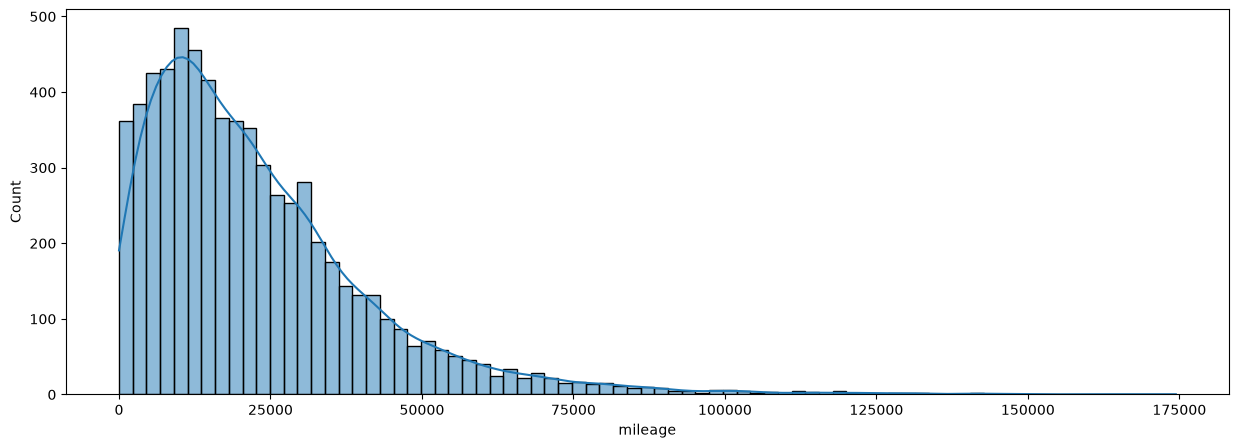

In [10]:
plt.figure(figsize=(15,5))
sns.histplot(df['mileage'], kde=True)
plt.show()

# Distribusi Harga Mobil

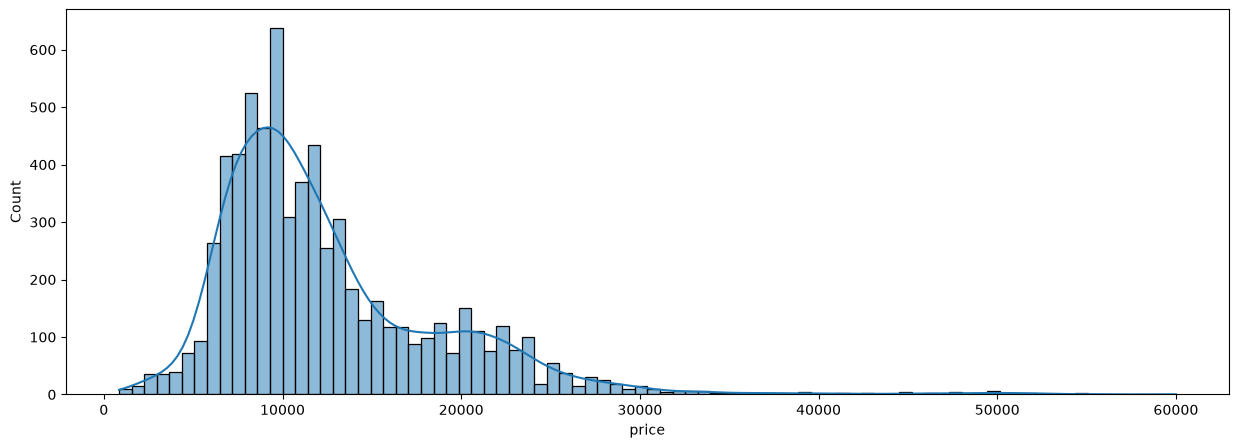

In [25]:
plt.figure(figsize=(15,5))
sns.histplot(df['price'], kde=True)
plt.show()

# Seleksi Fitur

In [26]:
features = ['year', 'mileage', 'tax', 'mpg', 'engineSize']

x = df[features]
y = df['price']

x.shape, y.shape

((6738, 5), (6738,))

# Split Data Training dan Data Testing

In [27]:
x_train, x_test, y_train, y_test = train_test_split(
    x, y, random_state=70
)

y_test.shape

(1685,)

# Membuat Model Regresi Linier

In [28]:
lr = LinearRegression()

lr.fit(x_train, y_train)

pred = lr.predict(x_test)

In [29]:
score = lr.score(x_test, y_test)

print('akurasi model regresi linier = ', score)

akurasi model regresi linier =  0.7678983314475204


In [21]:
hasil = pd.DataFrame({
    'Harga Aktual': y_test,
    'Harga Prediksi': pred
})

hasil.head(10)

,Harga Aktual,Harga Prediksi
591,17295,22474.996570
4338,7995,7827.324599
6255,18799,15833.431326
1396,11888,16191.481710
3350,16495,15564.987347
5430,4495,3523.098650
3475,4975,5200.352436
3310,17995,17168.487238
5648,23440,18404.659545
5674,20995,17185.531086


# Membuat inputan model regresi linier


In [31]:
Year = 2019
mileage = 5000
tax = 145
mpg = 30.2
engineSize = 2

input_data = np.array([[2019, 5000, 145, 30.2, 2]])

prediction = lr.predict(input_data)

print('Estimasi harga mobil dalam EUR :', prediction)

Estimasi harga mobil dalam EUR : [21208.50538579]


C:\Users\HP5CD\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


# Save model

In [32]:
import pickle

filename = 'estimasi_mobil.sav'
pickle.dump(lr,open(filename,'wb'))